# 1  The Maximal Overlap Discrete Wavelet Transform: Theory and Implementation

## 1.5 Implementation and Practical Methods

### 1.5.3 Decomposition Example

**1. Check the Coefficient Lengths**

In [1]:
from modwtpy.modwt import modwt
import numpy as np
import matplotlib.pyplot as plt

# Create a noisy sine wave signal
np.random.seed(0)
t = np.linspace(0, 1, 256)
signal = np.sin(2 * np.pi * 5 * t) + 0.5 * np.random.randn(256)

# Perform MODWT decomposition
coeffs = modwt(signal, 'db2', level=3)

# Extract coefficients
cD1, cD2, cD3, cA3 = coeffs

# Print lengths
print("Original signal length:", len(signal))
print("cD1 length:", len(cD1))
print("cD2 length:", len(cD2))
print("cD3 length:", len(cD3))
print("cA3 length:", len(cA3))


Original signal length: 256
cD1 length: 256
cD2 length: 256
cD3 length: 256
cA3 length: 256


**2. Visulize Decomisition Result**

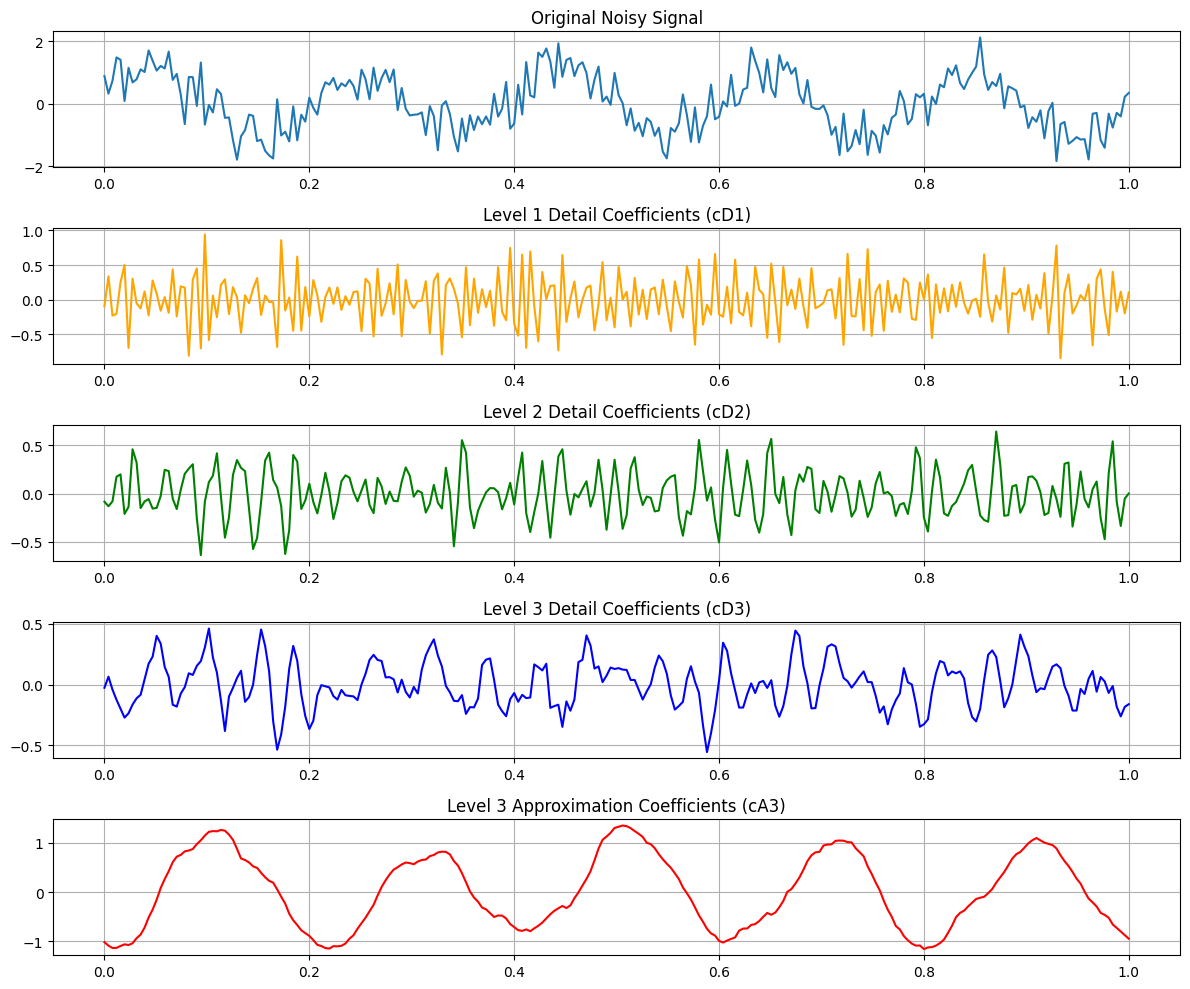

In [ ]:

# Plot signal and approximation and detail coefficients
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

plt.subplot(5, 1, 1)
plt.plot(t, signal, label="Noisy Signal")
plt.title("Original Noisy Signal")
plt.grid(True)

plt.subplot(5, 1, 2)
plt.plot(t, cD1, color='orange', label="Level 1 Detail (cD1)")
plt.title("Level 1 Detail Coefficients (cD1)")
plt.grid(True)

plt.subplot(5, 1, 3)
plt.plot(t, cD2, color='green', label="Level 2 Detail (cD2)")
plt.title("Level 2 Detail Coefficients (cD2)")
plt.grid(True)

plt.subplot(5, 1, 4)
plt.plot(t, cD3, color='blue', label="Level 3 Detail (cD3)")
plt.title("Level 3 Detail Coefficients (cD3)")
plt.grid(True)

plt.subplot(5, 1, 5)
plt.plot(t, cA3, color='red', label="Level 3 Approximation (cA3)")
plt.title("Level 3 Approximation Coefficients (cA3)")
plt.grid(True)

plt.tight_layout()
plt.savefig("./output/modwt_example.png")
plt.show()


**3. Energy Distribution**

In [9]:
import pandas as pd

# Compute energy = sum of squared coefficients
energies = {
    "D1": np.sum(cD1**2),
    "D2": np.sum(cD2**2),
    "D3": np.sum(cD3**2),
    "A3": np.sum(cA3**2),
}
total_energy = np.sum(signal**2)

# Build DataFrame for table
df = pd.DataFrame({
    "Energy": energies.values(),
    "Percentage (%)": [100 * e / total_energy for e in energies.values()]
}, index=energies.keys())

# Add total row
df.loc["Total"] = [total_energy, 100.0]

print("Energy Distribution Table:")
table_str = df.round(4).to_string()
print("-" * len(table_str.splitlines()[0]))
print(table_str)

Energy Distribution Table:
-------------------------------
         Energy  Percentage (%)
D1      30.5164         15.5022
D2      14.4242          7.3274
D3       9.0630          4.6040
A3     142.8485         72.5664
Total  196.8521        100.0000


### 1.5.4 MODWT Inverse Transform

Mean Absolute Error between original and reconstructed signal: 3.716373996737188e-16


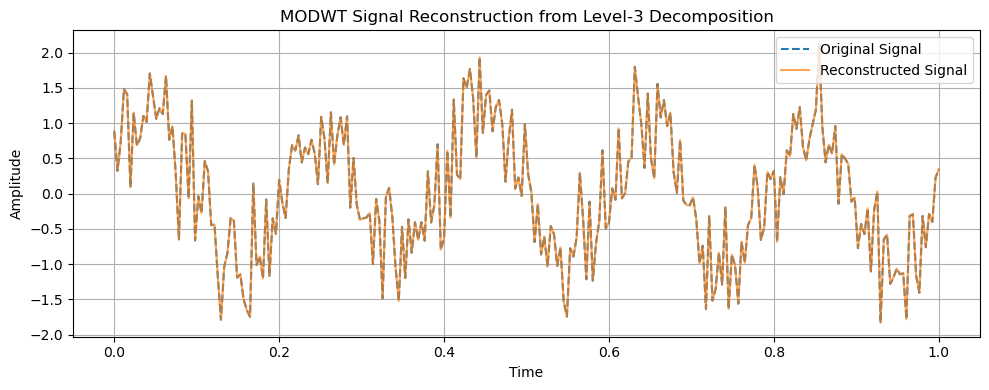

In [ ]:
from modwtpy.modwt import imodwt
import matplotlib.pyplot as plt

# Arrange coefficients in the correct order: [cD1, cD2, cD3, cA3]
coeffs = [cD1, cD2, cD3, cA3]

# Perform inverse MODWT to reconstruct the original signal
reconstructed = imodwt(coeffs, 'db2')

# Compare original and reconstructed signals
MAE = np.mean(np.abs(signal - reconstructed))
print(f"Mean Absolute Error between original and reconstructed signal: {MAE}")

# Plot original and reconstructed signals
plt.figure(figsize=(10, 4))
plt.plot(t, signal, label='Original Signal', linestyle='--')
plt.plot(t, reconstructed, label='Reconstructed Signal', alpha=0.7)
plt.title("MODWT Signal Reconstruction from Level-3 Decomposition")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("./output/modwt_reconstruction.png")
plt.show()


## 1.6 Advanced Applications

### 1.6.1 Partial Reconstruction

**1.  Reconstruct A₃, D₃, D₂, D₁ Separately from MODWT Coefficients**

In [16]:
# Perform MODWT decomposition
cD1, cD2, cD3, cA3 = modwt(signal, 'db2', level=3)

# Create zero arrays of same length
zero = np.zeros_like(cD1)

# Reconstruct components
A3 = imodwt([zero, zero, zero, cA3], 'db2')  # Approximation at level 3
D3 = imodwt([zero, zero, cD3, zero], 'db2')  # Detail at level 3
D2 = imodwt([zero, cD2, zero, zero], 'db2')  # Detail at level 2
D1 = imodwt([cD1, zero, zero, zero], 'db2')  # Detail at level 1

# Optional: verify reconstruction
reconstructed = A3 + D3 + D2 + D1
mae = np.mean(np.abs(signal - reconstructed))
print("MAE:", mae)

MAE: 3.828317871046316e-16


**2. Plot Each Component**

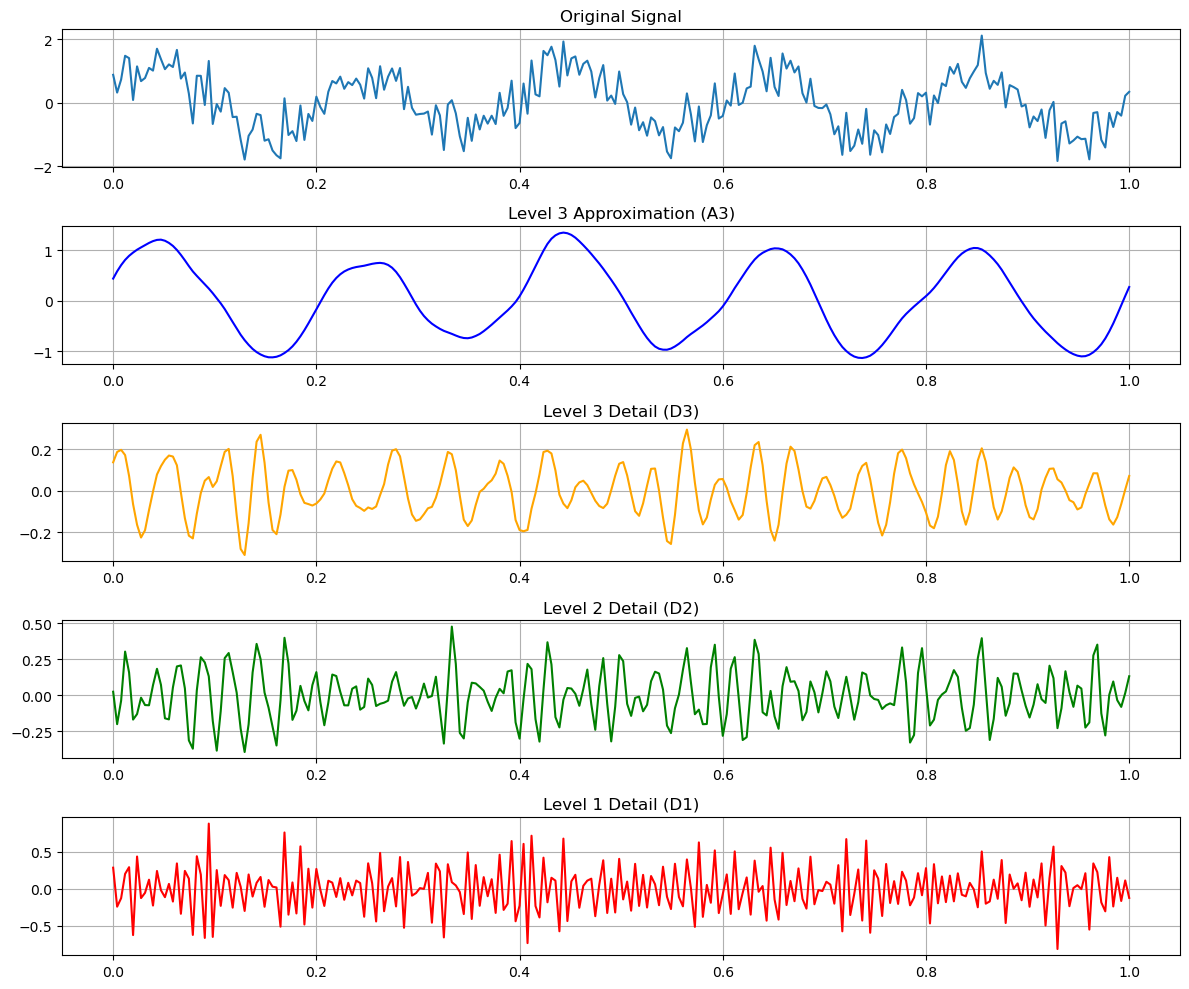

In [ ]:
plt.figure(figsize=(12, 10))

plt.subplot(5, 1, 1)
plt.plot(t, signal, label="Original Signal")
plt.title("Original Signal")
plt.grid(True)

plt.subplot(5, 1, 2)
plt.plot(t, A3, label="Approximation A3", color="blue")
plt.title("Level 3 Approximation (A3)")
plt.grid(True)

plt.subplot(5, 1, 3)
plt.plot(t, D3, label="Detail D3", color="orange")
plt.title("Level 3 Detail (D3)")
plt.grid(True)

plt.subplot(5, 1, 4)
plt.plot(t, D2, label="Detail D2", color="green")
plt.title("Level 2 Detail (D2)")
plt.grid(True)

plt.subplot(5, 1, 5)
plt.plot(t, D1, label="Detail D1", color="red")
plt.title("Level 1 Detail (D1)")
plt.grid(True)

plt.tight_layout()
plt.show()
plt.savefig("./output/modwt_partial_reconstruction.png")
plt.show()


### 1.6.3 Signal Denoising

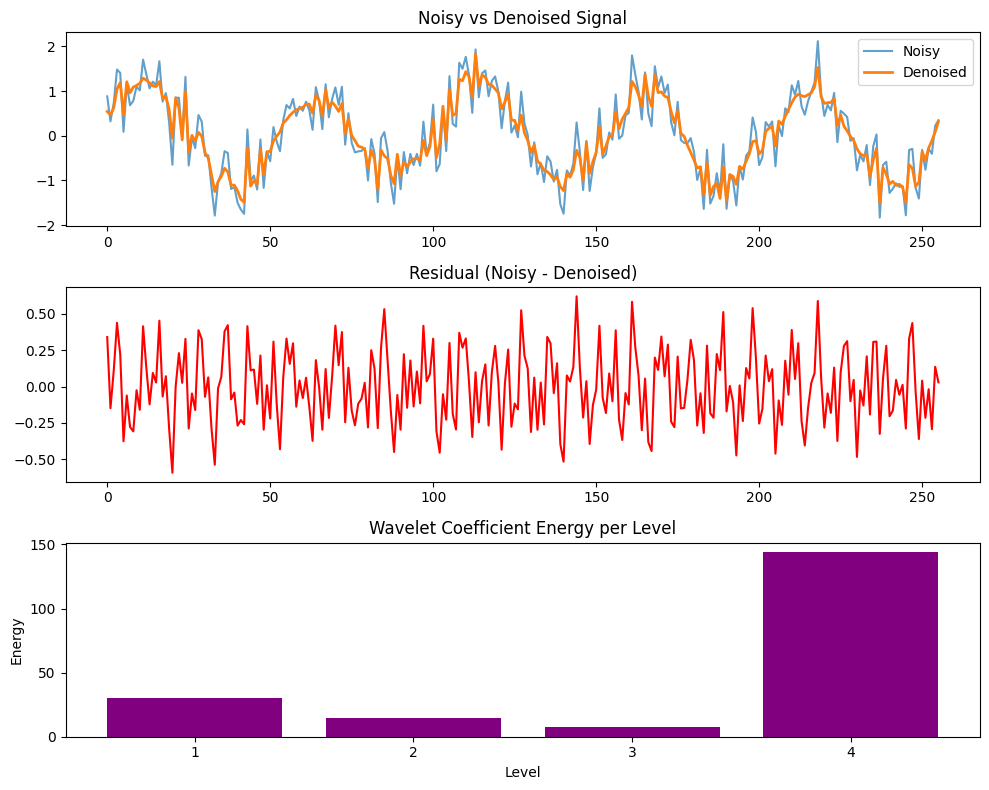

Evaluation Metrics:
MSE: 0.0641
RMSE: 0.2533
MAE: 0.2095
SNR (dB): 9.8049


In [ ]:
def denoise_signal(signal, wavelet='db4', levels=3, threshold=0.1):
    """
    Denoise a signal using MODWT with soft thresholding on detail coefficients.
    Also computes evaluation metrics and energy distribution.

    Returns:
        denoised (array): Denoised signal
        metrics (dict): Error and quality metrics
        energy (list): Energy distribution per level
    """
    import numpy as np
    from modwtpy.modwt import modwt, imodwt

    # Perform MODWT decomposition
    coeffs = modwt(signal, wavelet, levels)

    # Compute energy before thresholding
    energy = [np.sum(c**2) for c in coeffs]

    # Apply soft thresholding to detail coefficients only
    for i in range(levels):
        coeffs[i] = np.sign(coeffs[i]) * np.maximum(np.abs(coeffs[i]) - threshold, 0)

    # Reconstruct signal
    denoised = imodwt(coeffs, wavelet)

    # Compute error metrics
    mse = np.mean((signal - denoised) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(signal - denoised))
    snr = 10 * np.log10(np.sum(denoised**2) / np.sum((signal - denoised)**2))

    metrics = {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "SNR (dB)": snr
    }

    return denoised, metrics, energy


# ==== Usage and Plotting ====
# import matplotlib.pyplot as plt
# import numpy as np

# Example noisy signal
# t = np.linspace(0, 1, 1000)
# signal = np.sin(2 * np.pi * 10 * t) + 0.5 * np.random.randn(len(t))

denoised, metrics, energy = denoise_signal(signal, wavelet='db4', levels=3, threshold=0.2)

# Plot
fig, axs = plt.subplots(3, 1, figsize=(10, 8))

# 1. Original vs Denoised
axs[0].plot(signal, label="Noisy", alpha=0.7)
axs[0].plot(denoised, label="Denoised", linewidth=2)
axs[0].legend()
axs[0].set_title("Noisy vs Denoised Signal")

# 2. Residual
axs[1].plot(signal - denoised, color="red")
axs[1].set_title("Residual (Noisy - Denoised)")

# 3. Energy distribution
axs[2].bar(range(1, len(energy) + 1), energy, color="purple")
axs[2].set_xticks(range(1, len(energy) + 1))
axs[2].set_title("Wavelet Coefficient Energy per Level")
axs[2].set_xlabel("Level")
axs[2].set_ylabel("Energy")

plt.tight_layout()
plt.savefig("./output/modwt_denoising_eval.png")
plt.show()

# Print metrics
print("Evaluation Metrics:")
for k, v in metrics.items():
    print(f"{k}: {v:.4f}")


## 1.7 Applications in Time Series Analysis

### 1.7.1 Trend Extraction

**1. Trend Extraction Function**

In [12]:
def extract_trend(ts, trend_true=None, wavelet='db4', levels=4):
    """
    Extract the low-frequency trend from a time series using MODWT and 
    optionally evaluate against the true trend.

    Parameters:
        ts (array-like): Input time series.
        trend_true (array-like or None): True trend (if known, for evaluation).
        wavelet (str): Wavelet type (default: 'db4').
        levels (int): Number of decomposition levels.

    Returns:
        trend (array): Extracted trend component (approximation at final level).
        metrics (dict): Evaluation metrics (MSE, RMSE, MAE, R²) if trend_true given, else empty.
    """
    from modwtpy.modwt import modwt, imodwt
    import numpy as np

    # MODWT decomposition
    coeffs = modwt(ts, wavelet, levels)

    # Zero out all detail coefficients
    null_details = [np.zeros(len(ts)) for _ in range(levels)]

    # Keep only the approximation at the last level
    trend = imodwt(null_details + [coeffs[-1]], wavelet)

    # Compute evaluation metrics if ground truth is provided
    metrics = {}
    if trend_true is not None:
        mse = np.mean((trend_true - trend) ** 2)
        rmse = np.sqrt(mse)
        mae = np.mean(np.abs(trend_true - trend))
        r2 = 1 - np.sum((trend_true - trend) ** 2) / np.sum((trend_true - np.mean(trend_true)) ** 2)

        metrics = {
            "MSE": mse,
            "RMSE": rmse,
            "MAE": mae,
            "R²": r2
        }

    return trend, metrics

**2. Visualization of Trending Result**

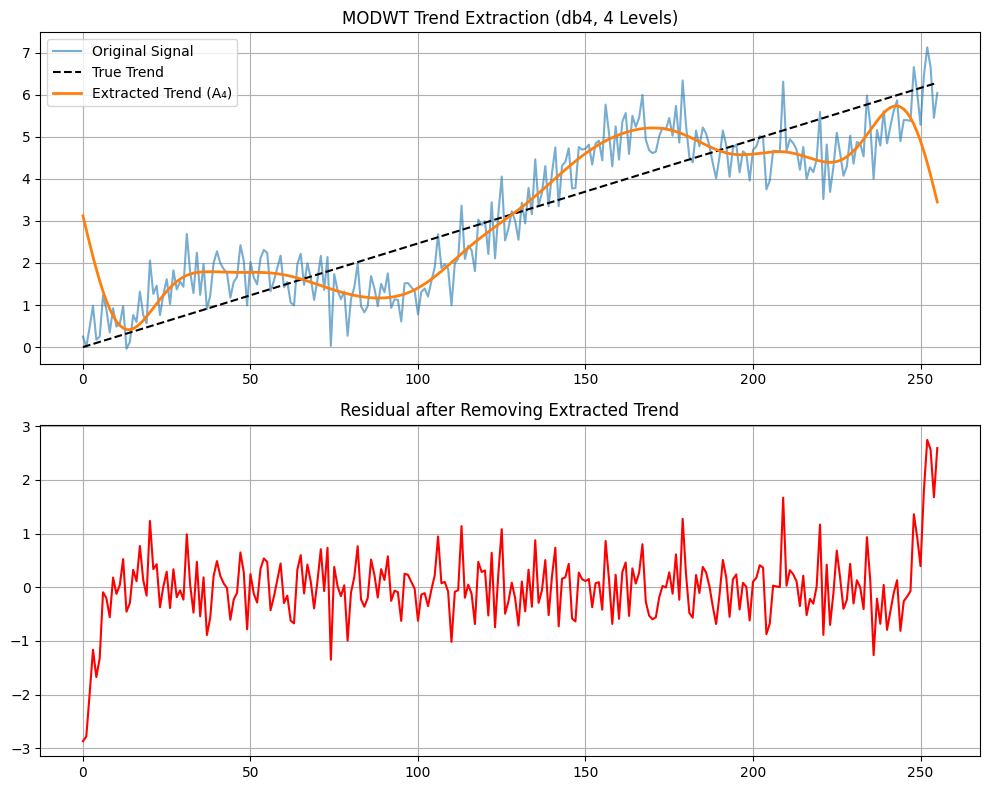

Trend Extraction Metrics:
MSE: 0.7020
RMSE: 0.8379
MAE: 0.6887
R²: 0.7883


In [ ]:
# ==== Example with synthetic signal ====
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n = 256
t = np.linspace(0, 4 * np.pi, n)
trend_true = 0.5 * t  # Linear trend
noise = 0.5 * np.random.randn(n)
signal = trend_true + np.sin(t) + noise  # Trend + oscillation + noise

# Extract trend + metrics
trend_est, metrics = extract_trend(signal, trend_true=trend_true, wavelet='db4', levels=4)

# Plot
fig, axs = plt.subplots(2, 1, figsize=(10, 8))
axs[0].plot(signal, label="Original Signal", alpha=0.6)
axs[0].plot(trend_true, label="True Trend", linestyle="--", color="black")
axs[0].plot(trend_est, label="Extracted Trend (A₄)", linewidth=2)
axs[0].set_title("MODWT Trend Extraction (db4, 4 Levels)")
axs[0].legend()
axs[0].grid(True)

axs[1].plot(signal - trend_est, color="red")
axs[1].set_title("Residual after Removing Extracted Trend")
axs[1].grid(True)

plt.tight_layout()
plt.savefig("./output/modwt_trend_extraction_eval.png")
plt.show()

# Print metrics
print("Trend Extraction Metrics:")
for k, v in metrics.items():
    print(f"{k}: {v:.4f}")


### 1.7.2 Anomaly Detection

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from modwtpy.modwt import modwt
from sklearn.metrics import precision_score, recall_score, f1_score

def detect_anomalies(ts, threshold_factor=3, wavelet='db1', level=1, true_anomalies=None):
    """
    Detect anomalies in a time series using MODWT detail coefficients.

    Parameters:
        ts (array-like): Input time series.
        threshold_factor (float): Multiplier for standard deviation threshold.
        wavelet (str): Wavelet type to use (default: 'db1').
        level (int): Decomposition level (default: 1, highest frequency).
        true_anomalies (array-like): Indices of true anomalies (optional).

    Returns:
        anomalies (np.ndarray): Indices of detected anomalies.
        details (np.ndarray): Detail coefficients used for detection.
        threshold (float): Computed threshold value.
        metrics (dict): Precision, Recall, F1 if true_anomalies provided, else empty.
    """
    # MODWT decomposition
    coeffs = modwt(ts, wavelet, level)
    details = coeffs[0]

    # Threshold
    threshold = threshold_factor * np.std(details)

    # Detected anomalies
    anomalies = np.where(np.abs(details) > threshold)[0]

    # Compute evaluation metrics if ground truth is provided
    metrics = {}
    if true_anomalies is not None:
        y_true = np.zeros(len(ts))
        y_true[true_anomalies] = 1
        y_pred = np.zeros(len(ts))
        y_pred[anomalies] = 1
        metrics = {
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1-score": f1_score(y_true, y_pred)
        }

    return anomalies, details, threshold, metrics


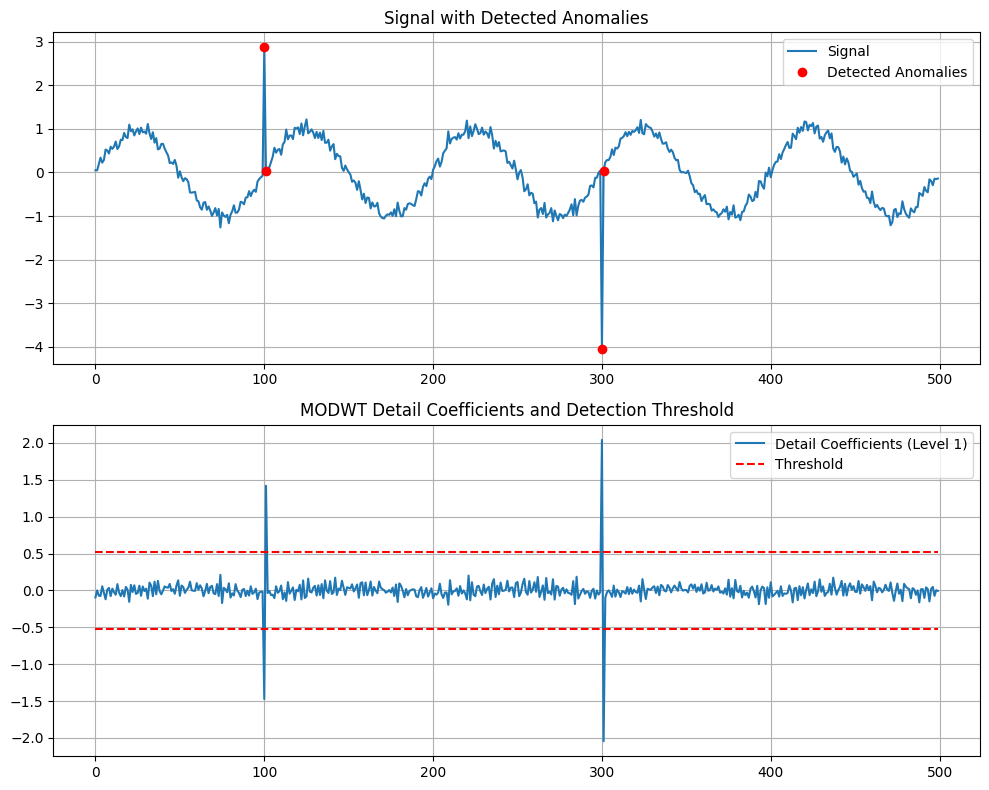

Anomaly Detection Metrics:
Precision: 0.5000
Recall: 1.0000
F1-score: 0.6667


In [ ]:
# ==== Example ====
np.random.seed(42)
ts = np.sin(np.linspace(0, 10*np.pi, 500)) + 0.1*np.random.randn(500)
true_anomalies = [100, 300]
ts[true_anomalies[0]] += 3
ts[true_anomalies[1]] -= 4

# Detect anomalies + metrics
anomalies, details, threshold, metrics = detect_anomalies(ts, threshold_factor=3, true_anomalies=true_anomalies)

# Plot
fig, axs = plt.subplots(2, 1, figsize=(10, 8))

# Signal with detected anomalies
axs[0].plot(ts, label="Signal")
axs[0].plot(anomalies, ts[anomalies], 'ro', label="Detected Anomalies")
axs[0].set_title("Signal with Detected Anomalies")
axs[0].legend()
axs[0].grid(True)

# Detail coefficients with threshold
axs[1].plot(details, label="Detail Coefficients (Level 1)")
axs[1].hlines([threshold, -threshold], 0, len(ts)-1, colors='r', linestyles='dashed', label='Threshold')
axs[1].set_title("MODWT Detail Coefficients and Detection Threshold")
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.savefig("./output/modwt_anomaly_detection_eval.png")
plt.show()

# Print metrics
print("Anomaly Detection Metrics:")
for k, v in metrics.items():
    print(f"{k}: {v:.4f}")
